# Разбор A. Почему одинаковая формула не решает вопрос идентичности?

Мы получили две карточки ксантинов. Коллега предлагает оставить одну: формула и молярная масса совпадают. Не будем спорить по названию. Построим проверку, которая показывает, какая информация скрыта за этим совпадением.

In [2]:
from pathlib import Path
import sys,json,math
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'programm/course.json').is_file())
sys.path.insert(0,str(ROOT/'practicuum/shared'))
from course_support import compound,workspace,write_json
from rdkit import Chem,rdBase
from rdkit.Chem import Descriptors,rdMolDescriptors,Draw
OUT=workspace('M03-L02','case')
rows=[]
molecules=[]
for name in ['theophylline','theobromine']:
    record=compound(name)
    molecule=Chem.MolFromSmiles(record['smiles'])
    if molecule is None:raise ValueError('Не разобрана запись: '+name)
    molecules.append(molecule)
    rows.append({'name':name,'cid':record['cid'],'source':record['source_url'],
       'formula':rdMolDescriptors.CalcMolFormula(molecule),
       'MW_g_mol':Descriptors.MolWt(molecule),
       'canonical_smiles':Chem.MolToSmiles(molecule,isomericSmiles=True)})
display(rows)


[{'name': 'theophylline',
  'cid': 2153,
  'source': 'https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/name/theophylline/property/MolecularFormula,MolecularWeight,CanonicalSMILES,IsomericSMILES,XLogP,TPSA/JSON',
  'formula': 'C7H8N4O2',
  'MW_g_mol': 180.167,
  'canonical_smiles': 'Cn1c(=O)c2[nH]cnc2n(C)c1=O'},
 {'name': 'theobromine',
  'cid': 5429,
  'source': 'https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/name/theobromine/property/MolecularFormula,MolecularWeight,CanonicalSMILES,IsomericSMILES,XLogP,TPSA/JSON',
  'formula': 'C7H8N4O2',
  'MW_g_mol': 180.16699999999997,
  'canonical_smiles': 'Cn1cnc2c1c(=O)[nH]c(=O)n2C'}]

Я выбираю именно пару теофиллин–теобромин, потому что она проверяет слабое место предполагаемой дедупликации. Если сравнить вещества с разными формулами, правило «объединять по формуле» легко их разделит, но мы ничего не узнаем о его поведении в трудном случае. Здесь нужно проверить, различает ли правило записи с одинаковым составом и разным соединением атомов.

Сначала сравниваю формулу, затем массу, затем канонические графы в одной и той же настройке RDKit. Масса в этом примере вычислена из состава и не служит независимым подтверждением идентичности. Третье сравнение проверяет то, что первые два оставляют незамеченным: как атомы соединены друг с другом.

Теперь предскажите результат трёх сравнений: формула, масса, каноническая запись. Не подменяем результат вопросом «похожи ли картинки»: выбираем проверяемые свойства графа.

{'same_formula': True, 'same_mass': True, 'same_canonical_graph': False}

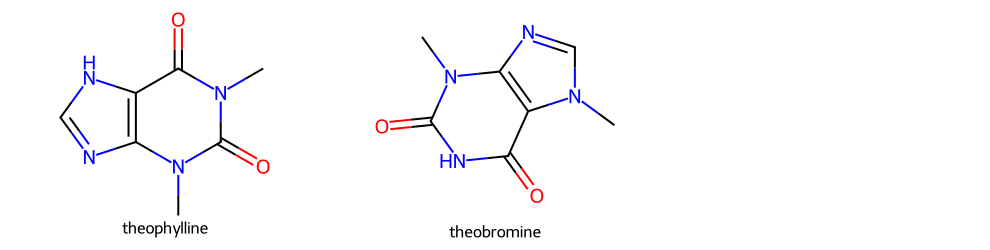

In [3]:
comparison={'same_formula':rows[0]['formula']==rows[1]['formula'],
            'same_mass':math.isclose(rows[0]['MW_g_mol'],rows[1]['MW_g_mol'],abs_tol=1e-9),
            'same_canonical_graph':rows[0]['canonical_smiles']==rows[1]['canonical_smiles']}
display(comparison)
assert comparison=={'same_formula':True,'same_mass':True,'same_canonical_graph':False}
# Визуализация помогает локализовать различие после вычислительной проверки.
display(Draw.MolsToGridImage(molecules,legends=[r['name'] for r in rows],subImgSize=(330,250)))


Первые два совпадения верны, но не достаточны для объединения. Посмотрите, где стоят метильные группы относительно атомов азота. Это конституционное различие, а не просто другой порядок символов. Из него ещё нельзя количественно вывести различие активности: для этого понадобятся биологические данные с сопоставимыми условиями.

Получив `True`, `True`, `False`, я не выбираю результат большинством голосов. У сравнений разная различающая способность. Если задача — не потерять разные конституционные структуры, решающим становится различие графов. Картинка после вычисления помогает локализовать его и объяснить коллеге, почему записи сохраняются раздельно.

Для форм аторвастатина следующий вопрос будет иным. Надо определить, описываем ли мы нейтральную кислоту, карбоксилат, соль как набор компонентов или лактон. Поэтому я переношу в B порядок постановки задачи и фиксации политики, а не готовое правило «любые разные строки — разные вещества».

Запишем политику: сохраняем самостоятельные записи и исходные структуры, разрешаем поиск по общей формуле, но не используем его как дедупликацию по полной идентичности. Подобное правило потребуется при работе с формами B, однако там придётся проверить ещё и компоненты/заряд.

In [4]:
passport={'rows':rows,'comparison':comparison,'rdkit':rdBase.rdkitVersion,
  'decision':'Не объединять конституционные изомеры по формуле или массе.',
  'next_check':'Для физического образца выбрать метод, способный различить предполагаемые изомеры, и сравнить со стандартами.'}
write_json(OUT/'isomer_comparison.json',passport)
print(OUT/'isomer_comparison.json')


C:\Users\Miakhlov\Documents\GitHub\Computational chemistry_course\tmp\reasoning-full-20261120\workspace\M03-L02\case\isomer_comparison.json


Проверьте понимание: каноническая строка решает сравнение при выбранной политике графа. Может ли она сама доказать, что содержимое неизвестной пробирки соответствует этой строке? Если нет, назовите недостающее звено.

# M03. Как наставник читает первичную работу

Пока следующая вычислительная задача ещё не выбрана, вернёмся к источнику: **Abo Horan et al. (2025). The Chemical Stability Characterization and Kinetics of Statins in Aqueous Cyclodextrin Ocular Preparations: A Formulation Perspective**. [Локальный полный текст](../../../../../shared/data/source-responses/statin_stability_verified.xml), [DOI](https://doi.org/10.3390/pharmaceutics17070808). Откройте **Methods и Figure 2 / Table 1**.

Найдите, как авторы различают лактонную и кислотную формы и начальные условия наблюдения.

Наставник начинает с вопроса «что здесь непосредственно наблюдали?». Найдите одно такое наблюдение и его место в источнике. Затем рядом запишите трактовку авторов и ещё одно возможное объяснение. Это учебный приём чтения, а не реконструкция мыслей авторов. Если численного ряда нет, вывод нельзя усиливать придуманными точками.

Перед вычислением назовите объект, условия, величину и единицы. После вычисления сравните ответ с исходным утверждением. При расхождении сначала проверьте форму вещества, основу концентрации и преобразования таблицы; только затем обсуждайте модель. Смысл операции — получить проверяемый аргумент для следующего решения досье.

Теперь перенесите приём на [самостоятельную мини-рецензию B](../steps/03_article_review.md). Для проверки собственного вывода используйте вопрос: **Можно ли перенести константу формы из одной среды на любую запись аторвастатина?**